# 03. Онлайн-симуляция и сравнение ЭЭГ / NIRS / гибрида

ТЗ §5.3: метрики считаются онлайн-симуляцией официальным каркасом (`solution/run.py` →
`solution/score.py`) на открытых `.mat`. Балл сессии: 60·min-F1 + 30·macro-recall гибрида + до 20 за
NIRS-only (5 за валидную матрицу + 15·min-F1 NIRS); глобально — среднее по сессиям.

**Протоколы.** Артефакты сдачи (`solution/artifacts/`) обучены на всех 56 сессиях, поэтому прогон
ими по train завышен. Честные цифры считаются тем же официальным каркасом с подменой артефактов:

* **хронологический (официальная цифра, `results/metrics/`)** — для сессии S все модели обучены
  только на сессиях, записанных раньше S (правило «обучаться можно на прошлом»);
* **LOSessO** — без самой сессии S (`results/metrics_loseso_final/`);
* **LOSubjO** — без всех сессий участника S (`results/metrics_losubjo_final/`).

Ниже: (1) живой прогон официального каркаса на нескольких сессиях (проверка контракта и
таймингов; `RUN_ALL = True` — на всех 56, ≈ 40 мин на 1 ядре); (2) анализ сохранённых прогонов
протоколов.

In [1]:
import os, sys, json, time, subprocess, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "assets":
    ROOT = ROOT.parent
SOL = ROOT / "solution"
sys.path.insert(0, str(SOL))
# каталог с сессиями *.mat (распакованный data.zip организаторов: data/Data/*.mat);
# переопределяется переменной окружения HORMIGAS_DATA
DATA = Path(os.environ.get("HORMIGAS_DATA", ROOT / "data" / "Data"))
SESSIONS = sorted(p for p in DATA.glob("*.mat") if p.name.lower() != "montage.mat")
MONTAGE = next((p for p in (DATA / "Montage.mat", DATA.parent / "Montage.mat") if p.exists()), None)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
CLASS_NAMES = {1: "покой", 2: "левая", 3: "правая"}
print("сессий:", len(SESSIONS), "| Montage.mat:", MONTAGE is not None)

сессий: 56 | Montage.mat: True


## 1. Живой прогон официального каркаса

In [2]:
RUN_ALL = False
subset = SESSIONS if RUN_ALL else [SESSIONS[0], SESSIONS[len(SESSIONS) // 2]]
out_root = Path(tempfile.mkdtemp(prefix="hormigas_runs_"))
env = dict(os.environ, OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1")
live = []
for p in subset:
    o = out_root / p.stem
    t0 = time.time()
    subprocess.run([sys.executable, str(SOL / "run.py"), "--input", str(p), "--output-dir", str(o),
                    "--artifacts", str(SOL / "artifacts")], check=True, env=env, capture_output=True)
    subprocess.run([sys.executable, str(SOL / "score.py"), "--session", str(p), "--predictions", str(o / "predictions.csv"),
                    "--timings", str(o / "timings.csv"), "--output", str(o / "metrics.json")], check=True, env=env, capture_output=True)
    m = json.loads((o / "metrics.json").read_text())
    live.append(dict(session=p.stem, wall_s=round(time.time() - t0), windows_match=m["windows_match"],
                     hyb_minF1=m["hybrid"]["min_f1"], hyb_recall=m["hybrid"]["macro_recall"],
                     nirs_minF1=(m["nirs_only"] or {}).get("min_f1"), predict_max_ms=m["timings"]["predict_max_s"] * 1e3,
                     fit_max_s=m["timings"]["fit_max_s"], penalties=m["timings"]["penalty_total"], total=m["score"]["total"]))
pd.DataFrame(live).round(3)

,session,wall_s,windows_match,hyb_minF1,hyb_recall,nirs_minF1,predict_max_ms,fit_max_s,penalties,total
0,2025.12.01.16.04.01_N01,43,True,0.787,0.824,0.555,0.038,0.765,0,85.268
1,2026.02.12.12.14.18_N11,44,True,0.936,0.951,0.499,0.020,0.802,0,97.186


Контракт выполняется (`windows_match`, без штрафов). Качество здесь — с артефактами, видевшими
эти сессии; дальше — честные протоколы.

## 2. Официальная цифра: хронологический протокол

In [3]:
def load_protocol(d):
    d = ROOT / d
    agg = json.loads((d / "metrics.json").read_text())
    return agg

P = {"хронологический (официальный)": "results/metrics", "LOSessO": "results/metrics_loseso_final",
     "LOSubjO": "results/metrics_losubjo_final"}
rows = []
for name, d in P.items():
    a = load_protocol(d)
    rows.append(dict(протокол=name, hyb_minF1=a["hybrid"]["min_f1"], hyb_recall=a["hybrid"]["macro_recall"],
                     base_60F_30P=a["score"]["base_quality"], nirs_minF1=a["nirs_only"]["min_f1"],
                     nirs_bonus=a["score"]["nirs_bonus"]["points"], penalties=a["score"]["penalties"],
                     total=a["score"]["total"]))
pd.DataFrame(rows).set_index("протокол").round(3)

,hyb_minF1,hyb_recall,base_60F_30P,nirs_minF1,nirs_bonus,penalties,total
протокол,,,,,,,
хронологический (официальный),0.621,0.732,59.192,0.441,11.621,0,70.814
LOSessO,0.662,0.760,62.529,0.477,12.154,0,74.683
LOSubjO,0.613,0.725,58.492,0.442,11.630,0,70.122


In [4]:
from score import confusion_from_preds, metrics_block, aggregate_session_metrics

def per_session(runs_dir):
    out = []
    for d in sorted((ROOT / runs_dir).iterdir()):
        pr = pd.read_csv(d / "predictions.csv")
        r = dict(session=d.name, subject=d.name.split("_")[-1])
        for col, tag in (("y", "hyb"), ("y_eeg", "eeg"), ("y_nirs", "nirs")):
            if col in pr and pr[col].notna().all():
                m = metrics_block(confusion_from_preds(pr.true_y.values, pr[col].values.astype(int)))
                r[f"{tag}_minF1"], r[f"{tag}_recall"] = m["min_f1"], m["macro_recall"]
        out.append(r)
    return pd.DataFrame(out)

ch = per_session("results/metrics/runs")
agg = json.loads((ROOT / "results/metrics/metrics.json").read_text())
print("пересчёт из predictions.csv совпадает с metrics.json:",
      np.isclose(ch.hyb_minF1.mean(), agg["hybrid"]["min_f1"]), np.isclose(ch.hyb_recall.mean(), agg["hybrid"]["macro_recall"]))
summary = pd.DataFrame({
    "min-F1": [ch.eeg_minF1.mean(), ch.nirs_minF1.mean(), ch.hyb_minF1.mean()],
    "macro-recall": [ch.eeg_recall.mean(), ch.nirs_recall.mean(), ch.hyb_recall.mean()],
    "сессий": [ch.eeg_minF1.notna().sum(), ch.nirs_minF1.notna().sum(), ch.hyb_minF1.notna().sum()]},
    index=["ЭЭГ-only", "NIRS-only", "гибрид ЭЭГ+NIRS"])
summary["60F+30P"] = 60 * summary["min-F1"] + 30 * summary["macro-recall"]
summary.round(3)

пересчёт из predictions.csv совпадает с metrics.json: True True


,min-F1,macro-recall,сессий,60F+30P
ЭЭГ-only,0.594,0.706,56,56.814
NIRS-only,0.441,0.583,54,43.979
гибрид ЭЭГ+NIRS,0.621,0.732,56,59.192


## 3. Даёт ли слияние выигрыш

Сравниваем на одних и тех же сессиях с NIRS (для сессий без NIRS гибрид = ЭЭГ-only).

сессий с NIRS: 54; выигрыш гибрида над ЭЭГ-only: +2.47 балла (медиана +2.54), лучше в 43 из 54; Wilcoxon p = 2.5e-05


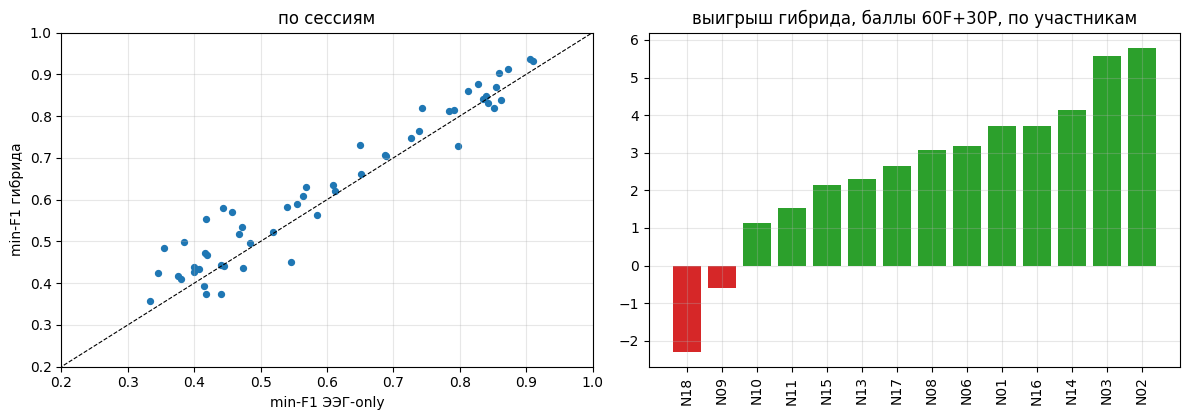

In [5]:
both = ch.dropna(subset=["nirs_minF1"])
gain = 60 * (both.hyb_minF1 - both.eeg_minF1) + 30 * (both.hyb_recall - both.eeg_recall)
from scipy.stats import wilcoxon
print(f"сессий с NIRS: {len(both)}; выигрыш гибрида над ЭЭГ-only: {gain.mean():+.2f} балла (медиана {gain.median():+.2f}),"
      f" лучше в {int((gain > 0).sum())} из {len(both)}; Wilcoxon p = {wilcoxon(gain).pvalue:.1e}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].scatter(both.eeg_minF1, both.hyb_minF1, s=18)
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set_xlim(0.2, 1); ax[0].set_ylim(0.2, 1)
ax[0].set_xlabel("min-F1 ЭЭГ-only"); ax[0].set_ylabel("min-F1 гибрида"); ax[0].set_title("по сессиям")
subj = both.assign(gain=gain).groupby("subject").gain.mean().sort_values()
ax[1].bar(subj.index, subj.values, color=np.where(subj.values > 0, "C2", "C3"))
ax[1].tick_params(axis="x", rotation=90); ax[1].set_title("выигрыш гибрида, баллы 60F+30P, по участникам")
plt.tight_layout(); plt.show()

## 4. Матрицы ошибок и дообучение по блокам

Суммарные матрицы — только для иллюстрации (официальная агрегация — среднее метрик по сессиям,
матрицы не суммируются).

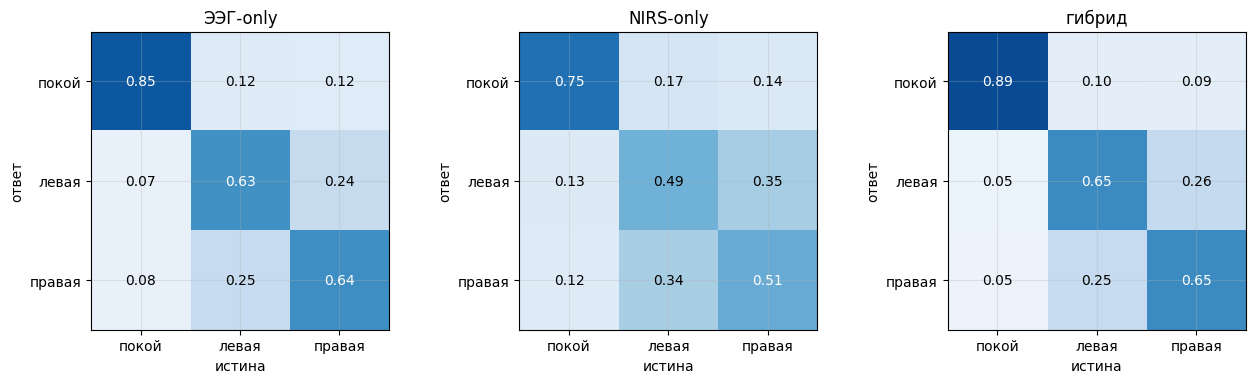

In [6]:
G = {k: np.zeros((3, 3)) for k in ("y_eeg", "y_nirs", "y")}
for d in sorted((ROOT / "results/metrics/runs").iterdir()):
    pr = pd.read_csv(d / "predictions.csv")
    for k in G:
        if k in pr and pr[k].notna().all():
            G[k] += confusion_from_preds(pr.true_y.values, pr[k].values.astype(int))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (k, title) in zip(axes, (("y_eeg", "ЭЭГ-only"), ("y_nirs", "NIRS-only"), ("y", "гибрид"))):
    g = G[k] / G[k].sum(0, keepdims=True)                       # столбцы — истинные классы
    ax.imshow(g, vmin=0, vmax=1, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{g[i, j]:.2f}", ha="center", va="center", color="w" if g[i, j] > 0.5 else "k")
    ax.set_xticks(range(3), CLASS_NAMES.values()); ax.set_yticks(range(3), CLASS_NAMES.values())
    ax.set_xlabel("истина"); ax.set_ylabel("ответ"); ax.set_title(title)
plt.tight_layout(); plt.show()

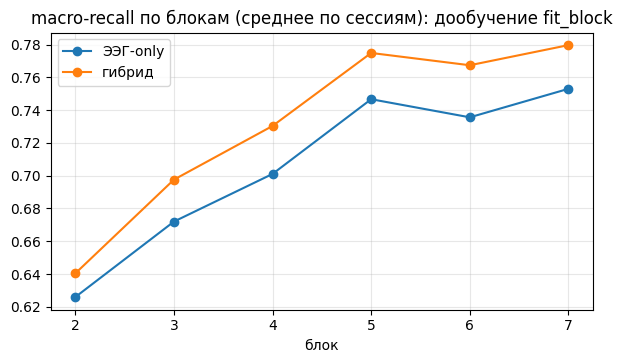

block,2,3,4,5,6,7
y_eeg,0.626,0.672,0.701,0.747,0.736,0.753
y,0.640,0.698,0.730,0.775,0.767,0.780


In [7]:
import io_utils as iu
acc = []
for p in SESSIONS:
    run = ROOT / "results/metrics/runs" / p.stem
    if not run.exists():
        continue
    pr = pd.read_csv(run / "predictions.csv")
    s = iu.load_session(p)
    pr["block"] = s["blocks"][pr.end_sample.values - 1]
    for b, g in pr.groupby("block"):
        r = dict(block=b)
        for col in ("y_eeg", "y"):
            m = metrics_block(confusion_from_preds(g.true_y.values, g[col].values.astype(int)))
            r[col] = m["macro_recall"]
        acc.append(r)
acc = pd.DataFrame(acc).groupby("block").mean()
ax = acc.rename(columns={"y_eeg": "ЭЭГ-only", "y": "гибрид"}).plot(marker="o", figsize=(7, 3.6))
ax.set_title("macro-recall по блокам (среднее по сессиям): дообучение fit_block"); ax.set_xlabel("блок"); plt.show()
acc.round(3).T

## 5. Тайминги (официальный каркас)

predict:   median 3.0 мкс, max 0.082 мс  (бюджет 200 мс)
fit_block: median 0.68 с, p95 0.81 с, max 0.89 с  (бюджет 1.5 с)


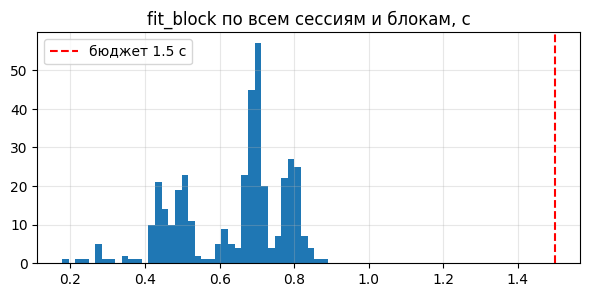

In [8]:
tp, tf = [], []
for d in sorted((ROOT / "results/metrics/runs").iterdir()):
    t = pd.read_csv(d / "timings.csv")
    tp.append(t[t.event == "predict"].seconds.values); tf.append(t[t.event == "fit_block"].seconds.values)
tp, tf = np.concatenate(tp), np.concatenate(tf)
print(f"predict:   median {np.median(tp) * 1e6:.1f} мкс, max {tp.max() * 1e3:.3f} мс  (бюджет 200 мс)")
print(f"fit_block: median {np.median(tf):.2f} с, p95 {np.quantile(tf, 0.95):.2f} с, max {tf.max():.2f} с  (бюджет 1.5 с)")
plt.figure(figsize=(7, 3)); plt.hist(tf, 40); plt.axvline(1.5, color="r", ls="--", label="бюджет 1.5 с")
plt.title("fit_block по всем сессиям и блокам, с"); plt.legend(); plt.show()

## 6. Как воспроизвести протоколы целиком

Нужны подменные артефакты протоколов (`data/features/{chrono,subjpool_loseso,eeg_models}`),
которые строятся скриптами из `src/` (см. `04_training_and_history.ipynb` и `report/REPORT.md`,
раздел «Воспроизведение»):

```bash
PY=python
$PY -m src.scripts.judge_eval --official solution --out <dir>/chrono  --jobs 4 --loseso-dir data/features/chrono
$PY -m src.scripts.judge_eval --official solution --out <dir>/loseso  --jobs 4 --loseso-dir data/features/subjpool_loseso
$PY -m src.scripts.judge_eval --official solution --out <dir>/losubjo --jobs 4
# артефакты сдачи на всех сессиях (как в разделе 1 при RUN_ALL=True):
$PY solution/tools/run_all.py --input <каталог .mat> --runs-dir <dir>/runs --metrics-dir <dir>/metrics
```